## today we practise polynomial regression 

In [1]:
# first we load the datase the

import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
 

In [3]:
df= pd.read_csv("train.csv")
df

,Year,AveTempChange
0,1972,-0.066723
1,2005,0.879251
2,1994,0.592248
3,1980,0.251915
4,1985,0.071294
5,1986,0.143533
6,2022,1.348951
7,2014,1.114077
8,1970,0.100147
9,2013,0.941955


In [19]:
df1=pd.read_csv("test.csv")
df1

,Year
0,1996
1,2004
2,1978
3,2021
4,2007
5,1992
6,1964
7,1993
8,2002
9,2019


Text(0, 0.5, 'Average temp')

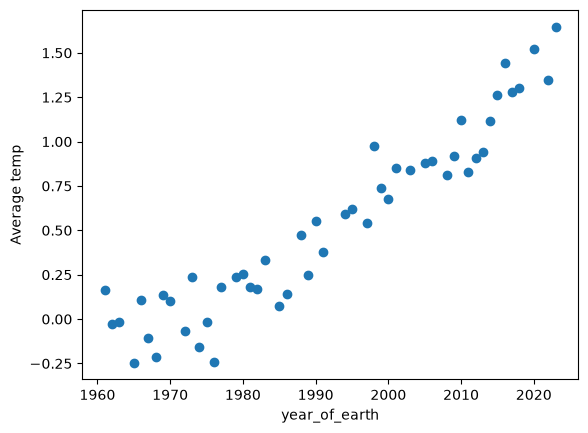

In [4]:
# first we show the graph 
plt.scatter(df["Year"],df["AveTempChange"])
plt.xlabel("year_of_earth")
plt.ylabel("Average temp")

## linear regression 



In [7]:
from sklearn.linear_model import LinearRegression



In [28]:
x_passed_value=df[["Year"]]
y_passed_value=df[["AveTempChange"]]
x_test=df1["Year"]


In [29]:
lr=LinearRegression()
lr.fit(x_passed_value,y_passed_value)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[0.03]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Year']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[-51.47]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [32]:
y_predicted=lr.predict(df1[["Year"]])
y_predicted

array([[ 0.65452893],
       [ 0.86345093],
       [ 0.18445442],
       [ 1.30741018],
       [ 0.94179668],
       [ 0.55006793],
       [-0.18115908],
       [ 0.57618318],
       [ 0.81122043],
       [ 1.25517968],
       [ 0.41949168],
       [ 0.00164767],
       [ 0.34114593]])

Text(0, 0.5, 'Average temp')

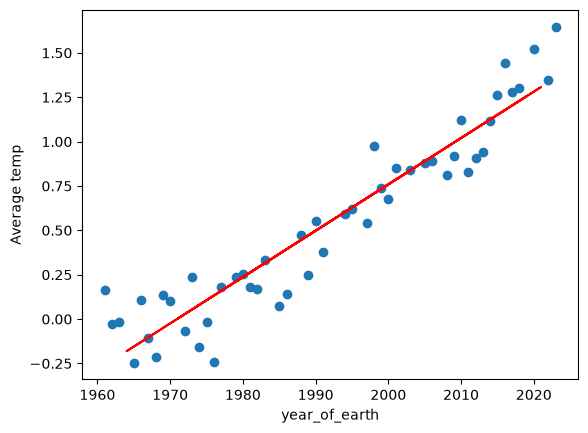

In [33]:
# first we show the graph 
plt.scatter(df["Year"],df["AveTempChange"])
plt.plot(x_test,y_predicted ,color="red")
plt.xlabel("year_of_earth")
plt.ylabel("Average temp")

In [39]:
from sklearn.metrics import mean_squared_error ,r2_score


In [40]:
mse =mean_squared_error(x_test,y_predicted)
mse 

r2=r2_score(x_test,y_predicted)
r2

-14634.432666659128

## ploynomial linear regression 

In [43]:
from sklearn.preprocessing  import PolynomialFeatures
from sklearn.linear_model import LinearRegression

In [53]:
x_test = df1[["Year"]]

In [54]:
# fit and transform 
poly =PolynomialFeatures(degree=5)
x_tt = poly.fit_transform(x_passed_value)
y_tt =poly.transform(x_test)



In [55]:
lr.fit(x_tt,y_passed_value)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 6)","[[ 0.,-0.,-0.,-0.,-0., 0.]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[96.17]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](6,)","[1.03e+16,1.64e+10,3.39e+04,2.94e-01,6.83e-02,0.00e+00]"


In [ ]:
y_predicted_poly = lr.predict(y_tt)


In [57]:
y_predicted_poly

array([[ 0.55779192],
       [ 0.80452994],
       [ 0.14031181],
       [ 1.45908489],
       [ 0.90703617],
       [ 0.44873338],
       [-0.05759684],
       [ 0.47511296],
       [ 0.73923369],
       [ 1.3726857 ],
       [ 0.32560995],
       [ 0.02782644],
       [ 0.2586949 ]])

In [63]:
# submission to kaggle compedition 


sub=pd.DataFrame({
    "Year":df1["Year"],
    "Predictions":y_predicted_poly.ravel()
})

In [64]:
sub.to_csv("sub1.csv",index=False)